# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате &lt;tool_call&gt;, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги {% generation %} в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: smart_home.py (симулятор и схемы пяти функций), chat_ui.py (чат),
data/ с train.jsonl, validation.jsonl и test_cases.jsonl.
Решение и результаты приведены ниже.

## Результат

Выполнил ДЗ на A100 40 GB. Обучил все веса Qwen2.5-0.5B-Instruct за три эпохи. Использовал learning rate 0.00002, batch 4, накопление градиентов 2, BF16 и assistant-only loss. Обучение заняло 142 секунды, весь ноутбук выполнился примерно за 4 минуты 20 секунд.

На 60 тестовых запросах доля правильных наборов функций выросла с 75,0% до 98,3%, а полное совпадение функций и аргументов с 43,3% до 96,7%. Это 59 из 60 запросов по выбору функций и 58 из 60 с правильными аргументами. Метрики отдельно для 40 английских и 20 русских запросов приведены в блоке 5 и в outputs/eval_results.csv.

Все пять сценариев агента прошли проверки. При относительном изменении температуры агент сначала прочитал состояние спальни, поднял температуру с 21 до 23 градусов, а по следующей просьбе до 25. На приветствие и просьбу открыть гараж инструменты не вызывались.


## 0. Окружение

Берём Instruct-модель: формат &lt;tool_call&gt; и токен конца реплики &lt;|im_end|&gt; она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
# Окружение: при первом запуске раскомментируй две строки ниже и перезапусти kernel (см. README.md).
# torch ставим именно с индекса cu126: колесо с PyPI по умолчанию собрано под CUDA 13 и требует драйвер >= 580.
# %pip install torch==2.8.0 --index-url https://download.pytorch.org/whl/cu126
# %pip install transformers==4.56.1 trl==0.23.1 datasets==3.6.0 accelerate==1.6.0 ipywidgets==8.1.9 matplotlib==3.10.1 pandas==2.2.3
import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)
torch.set_num_threads(4)
print("GPU:", torch.cuda.get_device_name(), "visible:", torch.cuda.device_count())
assert torch.cuda.device_count() == 1, "Выберите одну GPU через CUDA_VISIBLE_DEVICES"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")

GPU: NVIDIA A100-PCIE-40GB visible: 1


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 1. До обучения · 1 балл

Функция для модели - это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в apply_chat_template параметром tools: шаблон вставит их в system-реплику
и объяснит модели формат ответа &lt;tool_call&gt;. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите generate: сообщения и схемы функций проходят через apply_chat_template
с add_generation_prompt=True, декодирование жадное, стоп на &lt;|im_end|&gt; (это eos_token токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [3]:
@torch.inference_mode()
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    model.eval()
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, add_generation_prompt=True,
        tokenize=True, return_dict=True, return_tensors="pt",
    ).to(model.device)
    output = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        eos_token_id=tokenizer.convert_tokens_to_ids("<|im_end|>"),
        pad_token_id=tokenizer.pad_token_id,
    )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)


Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» -
модель подставляет в turn_light комнату garage, которой нет в схеме; «Turn off all lights» - придумывает
room: &quot;all&quot; вместо трёх вызовов; «Turn on the light» - выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool_call>"
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL - один диалог: messages и tools. Вызов функции - поле tool_calls
у реплики assistant, результат функции - отдельное сообщение с ролью tool.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова - не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона - ровно такой текст модель увидит на обучении. tool_calls стали блоками
&lt;tool_call&gt; внутри реплики assistant, а результат функции - блоком &lt;tool_response&gt; внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Разбор данных

В JSON результат функции имеет роль tool. Шаблон помещает его в блок user, потому что это входящая информация от симулятора. Модель должна прочитать результат и выбрать следующий ответ или действие. Если обучать её предсказывать tool_response, она начнёт учиться придумывать состояние дома вместо получения реального результата вызова. К тому же часть обучения будет уходить на текст, который модель вообще не должна выдавать пользователю.

- single_call учит выбирать одну функцию, заполнять аргументы и отвечать после её выполнения. Без этих примеров не будет основы для простых команд.
- parallel_calls учит выполнять несколько действий за один ответ. Например, для всех комнат нужны отдельные вызовы, а не выдуманное значение room: all. Без таких примеров модель будет пропускать часть команды или объединять аргументы неправильно.
- multi_turn учит учитывать историю и результаты инструментов. Это нужно для уточнений и относительного изменения температуры: сначала узнать состояние, затем посчитать новое значение. Без таких диалогов модель хуже справится с зависимыми действиями и продолжениями вроде «ещё на два градуса».
- no_call учит отвечать без инструментов, отказывать в неподдерживаемых действиях и уточнять недостающие аргументы. Без этого модель будет пытаться вызвать функцию даже для приветствия или команды открыть гараж.


## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, &lt;tool_call&gt; и &lt;|im_end|&gt;.
Запрос пользователя и результат функции она читает, но не предсказывает - у этих токенов label -100.
За это в TRL отвечает assistant_only_loss=True, а маску он строит по тегам
{% generation %}…{% endgeneration %} в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в {% generation %}…{% endgeneration %} вывод реплик assistant - и текст,
и tool_calls - и присвойте результат в tokenizer.chat_template. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [9]:
# Добавляем только границы маски, сохраняя текст исходного шаблона.
plain_branch = '    {%- if (message.role == "user") or (message.role == "system" and not loop.first) or (message.role == "assistant" and not message.tool_calls) %}'
masked_plain_branch = r"""    {%- if message.role == "assistant" and not message.tool_calls %}
        {{- '<|im_start|>assistant\n' }}{% generation %}{{- message.content + '<|im_end|>' + '\n' }}{% endgeneration %}
    {%- elif (message.role == "user") or (message.role == "system" and not loop.first) %}"""
assert NATIVE_TEMPLATE.count(plain_branch) == 1
TRAIN_TEMPLATE = NATIVE_TEMPLATE.replace(plain_branch, masked_plain_branch)
call_header = "        {{- '<|im_start|>' + message.role }}"
assert TRAIN_TEMPLATE.count(call_header) == 1
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(call_header, call_header + "{% generation %}")
call_end = '        {{- \'<|im_end|>\\n\' }}\n    {%- elif message.role == "tool" %}'
assert TRAIN_TEMPLATE.count(call_end) == 1
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(
    call_end, call_end.replace(" }}\n", " }}{% endgeneration %}\n", 1)
)
tokenizer.chat_template = TRAIN_TEMPLATE


In [10]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)

учим 89 из 764 токенов:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>

<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>
Готово, в гостиной теперь 30 градусов.<|im_end|>



In [11]:
for row in train_rows + validation_rows:
    native = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE)
    masked = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False)
    assert native == masked
print(f"Текст шаблона не изменился во всех {len(train_rows) + len(validation_rows)} диалогах.")


Текст шаблона не изменился во всех 922 диалогах.


## 4. Обучение · 3 балла

Данные и маска готовы. SFTTrainer сам применит шаблон к messages и tools, а assistant_only_loss=True
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [12]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните SFTConfig, создайте SFTTrainer, обучите модель и сохраните её в OUTPUT_DIR
(trainer.save_model() сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B - пара минут на A100.

In [13]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=3,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=2,
    learning_rate=2e-5,
    lr_scheduler_type="linear",
    warmup_ratio=0.1,
    weight_decay=0.01,
    optim="adamw_torch_fused",
    bf16=True,
    tf32=True,
    max_length=MAX_LENGTH,
    assistant_only_loss=True,
    completion_only_loss=False,
    packing=False,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=10,
    report_to="none",
    dataloader_num_workers=2,
    seed=SEED,
    data_seed=SEED,
    disable_tqdm=True,
)
model.config.use_cache = False
assert all(parameter.requires_grad for parameter in model.parameters())
trainer = SFTTrainer(
    model=model,
    args=config,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)
# Проверяем реальные labels, которые collator передаёт модели.
sample = trainer.train_dataset[0]
assert "assistant_masks" in sample
batch = trainer.data_collator([sample])
mask = torch.tensor(sample["assistant_masks"], dtype=torch.bool)
assert torch.equal(batch["labels"][0, :len(mask)].ne(-100), mask)
print("Loss считается только по токенам assistant; все веса обучаются.")
train_result = trainer.train()
trainer.save_model(str(OUTPUT_DIR))
assert (OUTPUT_DIR / "tokenizer_config.json").exists()


Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Loss считается только по токенам assistant; все веса обучаются.


... (30 outputs left out)

{'loss': 0.1105, 'grad_norm': 5.46875, 'learning_rate': 1.642857142857143e-06, 'entropy': 0.6754244595766068, 'num_tokens': 1761468.0, 'mean_token_accuracy': 0.9678473353385926, 'epoch': 2.7884615384615383}


{'loss': 0.122, 'grad_norm': 5.71875, 'learning_rate': 9.285714285714287e-07, 'entropy': 0.6825384020805358, 'num_tokens': 1823378.0, 'mean_token_accuracy': 0.9626359194517136, 'epoch': 2.8846153846153846}


{'loss': 0.0906, 'grad_norm': 6.0625, 'learning_rate': 2.142857142857143e-07, 'entropy': 0.687946480512619, 'num_tokens': 1882722.0, 'mean_token_accuracy': 0.9697991937398911, 'epoch': 2.980769230769231}


{'eval_loss': 0.30230244994163513, 'eval_runtime': 2.1129, 'eval_samples_per_second': 43.069, 'eval_steps_per_second': 21.771, 'eval_entropy': 0.697377429060314, 'eval_num_tokens': 1894875.0, 'eval_mean_token_accuracy': 0.9225475101367288, 'epoch': 3.0}
{'train_runtime': 141.8016, 'train_samples_per_second': 17.581, 'train_steps_per_second': 2.2, 'train_loss': 0.22058915198804477, 'epoch': 3.0}


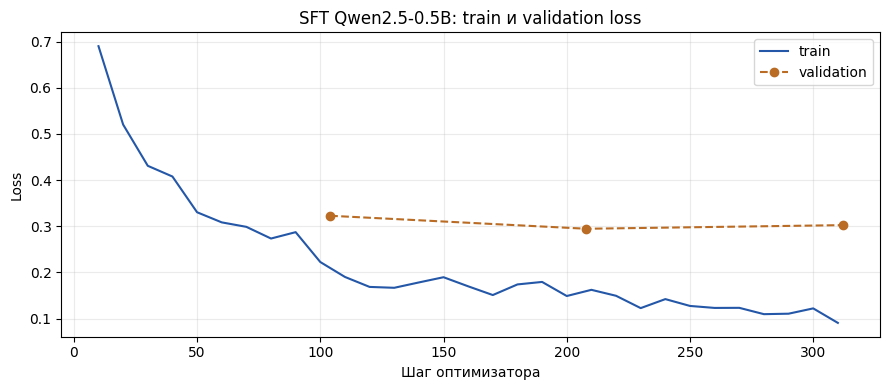

,epoch,step,eval_loss
10,1.0,104,0.322604
21,2.0,208,0.294473
33,3.0,312,0.302302


In [14]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])
history.to_json("outputs/training_history.json", orient="records", indent=2)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_log["step"], train_log["loss"], color="#2457a7", label="train")
ax.plot(eval_log["step"], eval_log["eval_loss"], color="#ba6c25", marker="o", linestyle="--", label="validation")
ax.set(xlabel="Шаг оптимизатора", ylabel="Loss", title="SFT Qwen2.5-0.5B: train и validation loss")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("outputs/loss.png", dpi=160)
plt.show()
display(eval_log[["epoch", "step", "eval_loss"]])


Validation loss после трёх эпох составил 0,3023. Минимум был после второй эпохи, 0,2945, затем он немного вырос, хотя train loss продолжал снижаться. Это похоже на начало переобучения. Для оценки функций использовал модель после всех трёх эпох, как и в остальных результатах ноутбука.


### Почему loss считаю только по ответам модели

Пользовательский запрос и результат инструмента уже даны модели на входе. Предсказывать их не нужно, поэтому их labels равны -100. В loss входят текст assistant, вызовы функций и конец реплики. Так модель учится и правильно вызывать инструмент, и вовремя заканчивать ответ.

Loss усредняется только по обучаемым токенам. Его нельзя напрямую сравнивать с loss по всему диалогу: набор токенов в среднем разный. Даже низкий loss сам по себе не гарантирует верные аргументы и правильную последовательность действий. Для этого ниже считаются tool_set_accuracy и exact_match и запускается агент.


## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на data/test_cases.jsonl: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- tool_set_accuracy - совпал набор вызванных функций (для запросов без вызова - модель ничего не вызвала);
- exact_match - совпали ещё и аргументы.

Битый &lt;tool_call&gt; или невалидный JSON - ошибка.

In [15]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [16]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()  # trainer мог оставить модель в train-режиме

cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")
scores = pd.concat([
    summarize(evaluate(base_model, tokenizer, cases)).assign(model="base"),
    summarize(evaluate(model, tokenizer, cases)).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
del base_model
gc.collect()
torch.cuda.empty_cache()

scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.750,0.55
1,base,ru,0.750,0.20
2,sft,en,0.975,0.95
3,sft,ru,1.000,1.00


Те же десять запросов: base-модель и обученная.

In [17]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)
comparison.to_csv("outputs/comparison.csv", index=False)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""cartons of milk""}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool_call>"
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?,"Hello! I can control lights and temperature in your kitchen, bedroom and living room, manage your shopping list and set timers. What would you like?"
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can turn the lights on or off in the kitchen, bedroom or living room, set the temperature there, add items to your shopping list or start timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>","Which room: kitchen, bedroom or living room?"


В таблице видно, что изменилось после SFT. На просьбу выключить весь свет базовая модель передавала room: all, а обученная сделала три вызова для существующих комнат. На просьбу открыть гараж базовая модель пыталась включить там свет, после обучения модель объясняет, что такого действия нет. Если комната не указана, обученная модель задаёт уточняющий вопрос вместо выбора комнаты наугад.

На русском тесте обе метрики достигли 100%. На английском осталась одна ошибка в наборе функций и две ошибки по полному совпадению. На таком небольшом тесте результат хороший, но он относится только к этим 60 запросам и пяти заданным функциям.


## 6. Агентный цикл · 2 балла

Модель печатает &lt;tool_call&gt;, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями tool → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
max_steps защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите run_agent: функция дописывает в messages реплики assistant
(с tool_calls в формате данных) и сообщения tool, пока модель не ответит текстом или не кончатся шаги.
Проверка - пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [18]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    for _ in range(max_steps):
        text = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(text)
        if calls is None:
            messages.append({"role": "assistant", "content": text})
            raise ValueError("Некорректный формат вызова инструмента")
        if not calls:
            messages.append({"role": "assistant", "content": text})
            return messages

        tool_calls = [
            {"id": f"call_{len(messages)}_{index}", "type": "function", "function": call}
            for index, call in enumerate(calls)
        ]
        messages.append({
            "role": "assistant", "content": TOOL_CALL_PATTERN.sub("", text).strip(),
            "tool_calls": tool_calls,
        })
        for call in tool_calls:
            function = call["function"]
            result = home.call(function["name"], function["arguments"])
            messages.append({
                "role": "tool", "name": function["name"], "tool_call_id": call["id"],
                "content": json.dumps(result, ensure_ascii=False),
            })
    raise RuntimeError(f"Агент достиг лимита {max_steps} шагов")


In [19]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
agent_results = []
for scenario_index, prompts in enumerate(scenarios):
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(home.snapshot(), ensure_ascii=False)}")
    # Повторяем только реальные вызовы в новом симуляторе и сверяем историю.
    replay = SmartHome()
    pending = []
    call_count = 0
    for message in messages:
        if message["role"] == "assistant":
            assert not pending, "Для части вызовов потеряны результаты"
            for call in message.get("tool_calls") or []:
                function = call["function"]
                pending.append((call["id"], function["name"], replay.call(function["name"], function["arguments"])))
                call_count += 1
        elif message["role"] == "tool":
            call_id, name, result = pending.pop(0)
            assert message["tool_call_id"] == call_id and message["name"] == name
            assert json.loads(message["content"]) == result
    assert not pending and replay.snapshot() == home.snapshot()
    if scenario_index == 0:
        assert home.rooms["kitchen"]["light"] == "on"
    elif scenario_index == 1:
        assert home.rooms["kitchen"] == {"light": "on", "temperature": 23}
    elif scenario_index == 2:
        assert home.rooms["bedroom"]["temperature"] == 25
        names = [c["function"]["name"] for m in messages for c in m.get("tool_calls") or []]
        assert names[0] == "get_room_state"
    else:
        assert call_count == 0
    agent_results.append({"scenario": scenario_index + 1, "prompts": prompts, "messages": messages, "state": home.snapshot(), "checks_passed": True})
    print("Проверки истории и состояния пройдены.")
Path("outputs/agent_results.json").write_text(json.dumps(agent_results, ensure_ascii=False, indent=2))


[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Проверки истории и состояния пройдены.


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Проверки истории и состояния пройдены.


[user] Make it two degrees warmer in the bedroom.
[assistant] 
    -> get_room_state({"room": "bedroom"})
[tool] {"room": "bedroom", "light": "off", "temperature": 21}
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 23})
[tool] {"room": "bedroom", "light": "off", "temperature": 23}
[assistant] The bedroom is now at 23 degrees.
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 25})
[tool] {"room": "bedroom", "light": "off", "temperature": 25}
[assistant] Done, the bedroom is at 25 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 25}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Проверки истории и состояния пройдены.
[user] Thanks!
[assistant] You're welcome!
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "s

[user] Open the garage.
[assistant] I can't control the garage. I can turn the lights on or off in the kitchen, bedroom or living room, set the temperature there, add items to your shopping list or start timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Проверки истории и состояния пройдены.


8236

Тот же run_agent в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте Turn off all lights., Add milk to my shopping list., Set a 5-minute timer labeled tea.

In [20]:
launch_chat(model, tokenizer, SmartHome(), run_agent)